# Spiral Classifier

## Network (inference)

$$
h = f(W_h x + b_h)
$$

$$
\hat{y} = g(W_y h + b_y)
$$

$$
f, g = (\cdot)^+,\ \sigma(\cdot),\ \tanh(\cdot),\ \operatorname{softmax}(\cdot)
$$

### Parameters

$$
W_h \in \mathbb{R}^{d \times n}, \quad b_h \in \mathbb{R}^{d}
$$

$$
W_y \in \mathbb{R}^{K \times d}, \quad b_y \in \mathbb{R}^{K}
$$

## Mapping

$$
\hat{y} = \hat{y}(x), \quad \hat{y}: \mathbb{R}^n \to \mathbb{R}^K, \quad x \mapsto \hat{y}
$$

$$
\hat{y}: \mathbb{R}^n \to \mathbb{R}^d \to \mathbb{R}^K, \quad d \gg n, K
$$


## Softmax and loss

Logits: output of the final layer, $\boldsymbol{l} = W_y h + b_y \in \mathbb{R}^K$

$$
\operatorname{softmax}(\boldsymbol{l})[c] \doteq \frac{\exp(l[c])}{\sum_{k=1}^{K} \exp(l[k])} \in (0, 1)
$$

$$
\mathcal{L}(\hat{Y}, \boldsymbol{c}) \doteq \frac{1}{m} \sum_{i=1}^{m} \ell(\hat{y}^{(i)}, c_i),
$$

$$
J(\Theta) \doteq \{W_h\}
$$


In [55]:
import numpy as np
import matplotlib.pyplot as plt

PLT_BG = "0.1"  # grayscale string: 0 = black, 1 = white -> light gray
plt.rcParams["figure.facecolor"] = PLT_BG
plt.rcParams["axes.facecolor"] = PLT_BG
plt.rcParams["savefig.facecolor"] = PLT_BG  # saved images stay gray too


def plot_data(X, y):
    """Scatter plot of 2-D data X colored by class labels y."""
    X = X.detach().cpu().numpy()
    y = y.detach().cpu().numpy()
    fig = plt.figure(figsize=(6, 6), facecolor=PLT_BG)
    ax = fig.add_subplot(111, facecolor=PLT_BG)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Spectral, s=8, edgecolors="none")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    plt.show()


def plot_model(X, y, model, step=0.01, alpha=0.35):
    """Decision regions of `model` under the data, with the data points on top."""
    import torch  # this cell otherwise only needs numpy/matplotlib

    device = next(model.parameters()).device
    Xn = X.detach().cpu().numpy()
    yn = y.detach().cpu().numpy()

    # Close figures left open by earlier runs: the inline backend re-renders
    # every open figure at the end of a cell, which is what made plots crawl.
    plt.close("all")
    fig, ax = plt.subplots(figsize=(6, 6), facecolor=PLT_BG)
    ax.set_facecolor(PLT_BG)

    # bounding box around the data, with a small margin
    x_min, x_max = Xn[:, 0].min() - 0.1, Xn[:, 0].max() + 0.1
    y_min, y_max = Xn[:, 1].min() - 0.1, Xn[:, 1].max() + 0.1

    # classify one grid point every `step` units
    xx, yy = np.meshgrid(np.arange(x_min, x_max, step),
                         np.arange(y_min, y_max, step))
    grid = torch.as_tensor(np.c_[xx.ravel(), yy.ravel()],
                           dtype=torch.float32, device=device)

    was_training = model.training
    if was_training:
        model.eval()  # no dropout/BN noise in the picture
    try:
        with torch.no_grad():  # no graph needed for a plot
            zz = model(grid).argmax(dim=1).cpu().numpy().reshape(xx.shape)
    finally:
        if was_training:
            model.train()

    # One colour per class. pcolormesh rasterises the grid directly; contourf
    # would extract polygons for every cell (much slower, and blank if a class
    # is never predicted). Same vmin/vmax on both calls keeps the colours aligned.
    n_classes = int(yn.max()) + 1
    vmin, vmax = -0.5, n_classes - 0.5
    ax.pcolormesh(xx, yy, zz, cmap=plt.cm.Spectral, alpha=alpha,
                  shading="auto", vmin=vmin, vmax=vmax)
    ax.scatter(Xn[:, 0], Xn[:, 1], c=yn, cmap=plt.cm.Spectral, s=8,
               edgecolors="none", vmin=vmin, vmax=vmax)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    plt.show()
    plt.close(fig)  # do not leave it in pyplot's registry
    return ax



Shapes:
X: (3000, 2)
y: (3000,)


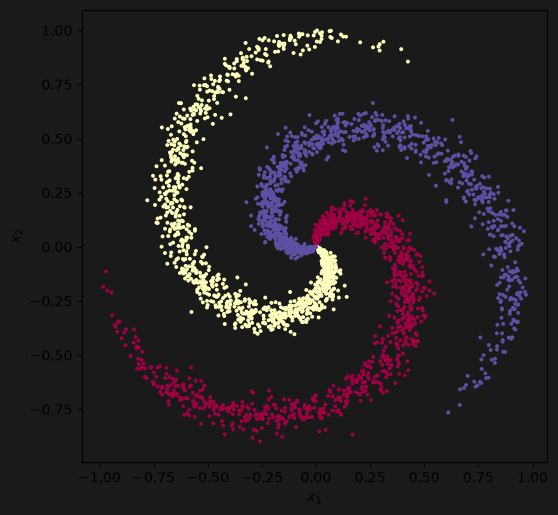

In [56]:
import random
import torch
from torch import nn, optim
import math
from IPython import display

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

seed = 12345
random.seed(seed)
torch.manual_seed(seed)

N = 1000 # num samples per class
D = 2    # dimensions
C = 3    # num classes
H = 100  # num hidden units

X = torch.zeros(N * C, D).to(device)
y = torch.zeros(N * C, dtype=torch.long).to(device)

for c in range(C):
    index = 0
    t = torch.linspace(0, 1, N)
    # When c = 0 and t = 0: start of linspace
    # When c = 0 and t = 1: end of linspace
    # This inner_var is for the formula inside sin() and cos() like sin(inner_var)
    inner_var = (
        torch.linspace((2 * math.pi / C) * (c), (2 * math.pi / C) * (2 + c), N)
        + torch.randn(N) * 0.2
    )

    for ix in range(N * c, N * (c + 1)):
        X[ix] = t[index] * torch.FloatTensor((
            math.sin(inner_var[index]), math.cos(inner_var[index])
        ))
        y[ix] = c
        index += 1

print("Shapes:")
print("X:", tuple(X.size()))
print("y:", tuple(y.size()))

# vizualize the data
plot_data(X, y)


## Linear model

In [57]:
learning_rate = 1e-3
lambda_12 = 1e-5

In [ ]:
# nn package to create our linear model
# each Linear module has a weight an bias
model = nn.Sequential(
    nn.Linear(D, H),
    nn.ReLU(),
    nn.Linear(H, C)
)
model.to(device) #Convert to CUDA

# nn package also has different loss functions.
# we use cross entropy loss for our classification task
criterion = torch.nn.CrossEntropyLoss()

# we use the optim package to apply SGD for our parameter updates
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate,
                            weight_decay=lambda_12)

# Training
for t in range(5000):
    # Feed forward to get the logits
    y_pred = model(X)

    # Compute the loss and accuracy
    loss = criterion(y_pred, y)
    score, predicted = torch.max(y_pred, 1)
    acc = (y == predicted).sum().float() / len(y)
    print("[EPOCH: %i, [LOSS]: %.6f, [ACCURACY]: %.3f" % (t,loss, acc))
    display.clear_output(wait=True)

    # zero the gradients before running the backward pass.
    optimizer.zero_grad()

    # Backward pass to compute the gradient
    # of loss w.r.t our learnable params.
    loss.backward()

    # Update params
    optimizer.step()


[EPOCH: 999, [LOSS]: 0.947456, [ACCURACY]: 0.537


Sequential(
  (0): Linear(in_features=2, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=3, bias=True)
)


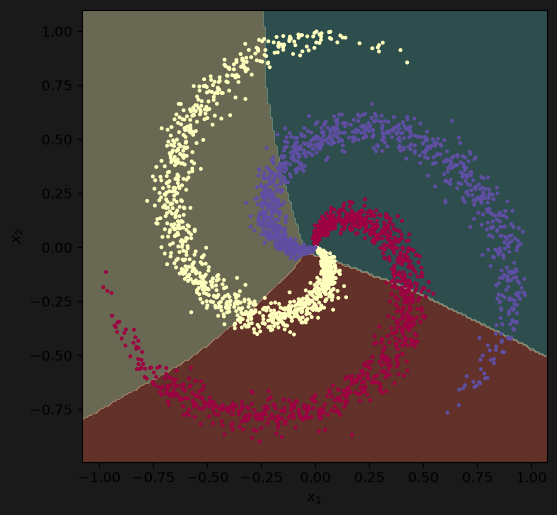

(<Figure size 600x600 with 1 Axes>, <Axes: xlabel='$x_1$', ylabel='$x_2$'>)

In [59]:

# Plot trained model
print(model)
plot_model(X, y, model)